# MindCheck – Depression & Anxiety Screener

In [2]:
import os

In [3]:
import numpy as np

In [4]:
import pandas as pd

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

In [7]:
DATA_DIR = "data"
files = ["phq9", "gad7", "isi", "pss", "demographic"]

In [8]:
for f in files:
    path = os.path.join(DATA_DIR, f + ".csv")
    print(f, "found:", os.path.exists(path))

phq9 found: True
gad7 found: True
isi found: True
pss found: True
demographic found: True


In [9]:
raw = {}
for f in files:
    raw[f] = pd.read_csv(os.path.join(DATA_DIR, f + ".csv"))

In [10]:
for f in files:
    print(f, "shape:", raw[f].shape)

phq9 shape: (24292, 20)
gad7 shape: (24292, 16)
isi shape: (24292, 16)
pss shape: (24292, 30)
demographic shape: (24292, 6)


In [11]:
print(raw["phq9"].head(3))

   export_id  score  question1  time1  question2  time2  question3  time3  \
0      61793      0          0   2.47          0   1.23          0   1.12   
1      61809      0          0   8.22          0   7.08          0   1.24   
2      61737      0          0   1.88          0   1.65          0   1.00   

   question4  time4  question5  time5  question6  time6  question7  time7  \
0          0   1.73          0   4.74          0   1.32          0   0.16   
1          0   1.08          0   1.77          0   1.26          0   1.05   
2          0   1.18          0   0.81          0   1.29          0   4.17   

   question8  time8  question9  time9  
0          0  12.99          0   4.00  
1          0   2.07          0   3.76  
2          0   1.29          0   4.58  


In [12]:
print(raw["pss"].head(3))

   export_id  score  question1  time1  question2  time2  question3  time3  \
0      61793      2          1   2.59          1   2.12          1   2.83   
1      61809     21          2   5.10          1   3.97          1   0.97   
2      61737      4          1   7.44          1   2.74          1   1.76   

   question4  time4  question5  time5  question6  time6  question7  time7  \
0          1   0.72          1   3.94          1   2.98          1   9.41   
1          5   0.77          5   0.78          2  11.83          4   4.47   
2          1   3.82          1   2.83          1   2.25          1   1.43   

   question8  time8  question9  time9  question10  time10  question11  time11  \
0          1   4.68          1   2.37           1    3.88           1    2.80   
1          2   3.64          2   8.50           5    2.78           1    1.91   
2          1   8.20          1   4.11           1    2.73           1    5.56   

   question12  time12  question13  time13  question14  ti

In [13]:
print(raw["demographic"].head(3))

   export_id  gender   age                edu         smoke  \
0      61793  female  19.0  bachelor's degree  never smokes   
1      61809  female  18.0  bachelor's degree  never smokes   
2      61737    male  40.0    master's degree  never smokes   

                                         drink  
0                                 never drinks  
1                                 never drinks  
2  drinks occasionally (less than once a week)  


In [14]:
for f in files:
    print(f, "missing values:", int(raw[f].isnull().sum().sum()))

phq9 missing values: 0
gad7 missing values: 0
isi missing values: 0
pss missing values: 0
demographic missing values: 0


In [15]:
for f in files:
    print(f, "duplicate IDs:", raw[f]["export_id"].duplicated().sum())

phq9 duplicate IDs: 0
gad7 duplicate IDs: 0
isi duplicate IDs: 0
pss duplicate IDs: 0
demographic duplicate IDs: 0


In [16]:
for f in files:
    print(f, "duplicate rows:", raw[f].duplicated().sum())

phq9 duplicate rows: 0
gad7 duplicate rows: 0
isi duplicate rows: 0
pss duplicate rows: 0
demographic duplicate rows: 0


In [17]:
id_sets = [set(raw[f]["export_id"]) for f in files]
common_ids = set.intersection(*id_sets)
print("IDs in every file:", len(common_ids))
print("IDs in phq9:", len(id_sets[0]))

IDs in every file: 24292
IDs in phq9: 24292


In [18]:
for f in ["phq9", "gad7", "isi", "pss"]:
    q_cols = [c for c in raw[f].columns if c.startswith("question")]
    print(f, "| questions:", len(q_cols), "| min:", raw[f][q_cols].min().min(), "| max:", raw[f][q_cols].max().max())

phq9 | questions: 9 | min: 0 | max: 3
gad7 | questions: 7 | min: 0 | max: 3
isi | questions: 7 | min: 0 | max: 4
pss | questions: 14 | min: 1 | max: 5


In [19]:
for f in ["phq9", "gad7", "isi", "pss"]:
    q_cols = [c for c in raw[f].columns if c.startswith("question")]
    match = (raw[f][q_cols].sum(axis=1) == raw[f]["score"]).mean()
    print(f, "score equals sum of answers:", round(match * 100, 1), "%")

phq9 score equals sum of answers: 100.0 %
gad7 score equals sum of answers: 100.0 %
isi score equals sum of answers: 100.0 %
pss score equals sum of answers: 0.0 %


In [20]:
print(raw["phq9"]["score"].describe().round(2))

count    24292.00
mean         3.27
std          3.71
min          0.00
25%          0.00
50%          2.00
75%          5.00
max         27.00
Name: score, dtype: float64


In [21]:
print(raw["gad7"]["score"].describe().round(2))

count    24292.00
mean         1.91
std          2.92
min          0.00
25%          0.00
50%          0.00
75%          3.00
max         21.00
Name: score, dtype: float64


In [22]:
demo_raw = raw["demographic"]
print(demo_raw["age"].describe().round(2))

count    24292.00
mean        20.66
std          2.41
min          1.00
25%         19.00
50%         20.00
75%         22.00
max         99.00
Name: age, dtype: float64


In [23]:
for col in ["gender", "edu", "smoke", "drink"]:
    print("\n", col)
    print(demo_raw[col].value_counts())


 gender
gender
female    15545
male       8747
Name: count, dtype: int64

 edu
edu
bachelor's degree    22290
associate degree      1285
master's degree        675
doctorate degree        42
Name: count, dtype: int64

 smoke
smoke
never smokes                                                              22513
occasional smoker (cumulative smoking <10 packs)                           1044
current smoker (cumulative smoking >10 packs)                               542
former smoker (cumulative smoking >10 packs), but not in the past year      193
Name: count, dtype: int64

 drink
drink
never drinks                                                           16404
drinks occasionally (less than once a week)                             7359
drank in the past (more than once a week), but not in the past year      284
current regular drinker (more than once a week)                          245
Name: count, dtype: int64


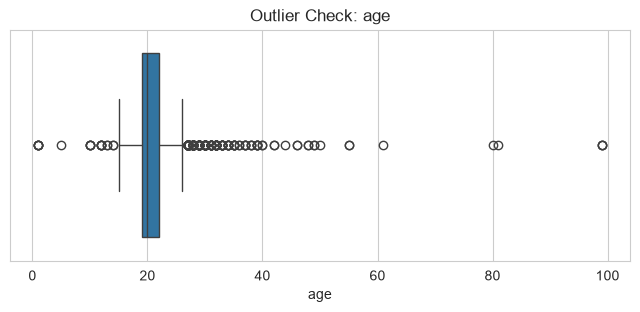

In [24]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=demo_raw["age"])
plt.title("Outlier Check: age")
plt.show()

In [25]:
q1 = demo_raw["age"].quantile(0.25)
q3 = demo_raw["age"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Flagged Values:", ((demo_raw["age"] < lower) | (demo_raw["age"] > upper)).sum())

Lower Bound: 14.5
Upper Bound: 26.5
Flagged Values: 299


IQR se normal students ki age 14.5-26.5 aati hai, par college students 40 tak ho sakte hain. Isliye 16-40 rakhenge.

In [26]:
print("Age < 16:", (demo_raw["age"] < 16).sum())
print("Age > 40:", (demo_raw["age"] > 40).sum())

Age < 16: 22
Age > 40: 18


In [27]:
time_cols = [c for c in raw["phq9"].columns if c.startswith("time")]
all_times = raw["phq9"][time_cols].stack()
print(all_times.describe().round(2))

count    218628.00
mean          4.73
std          25.73
min           0.01
25%           1.69
50%           3.00
75%           5.07
max        5370.34
dtype: float64


In [28]:
print("Answers taking more than 300 sec:", (all_times > 300).sum())

Answers taking more than 300 sec: 90


In [29]:
def prepare(name):
    d = raw[name].copy()
    d = d.rename(columns={"export_id": "id"})
    q_cols = [c for c in d.columns if c.startswith("question")]
    t_cols = [c for c in d.columns if c.startswith("time")]
    out = pd.DataFrame({"id": d["id"], name + "_score": d["score"]})
    for c in q_cols:
        out[name + "_" + c.replace("question", "q")] = d[c]
    out[name + "_time"] = d[t_cols].sum(axis=1)
    return out

In [30]:
phq = prepare("phq9")
gad = prepare("gad7")
isi = prepare("isi")
pss = prepare("pss")

In [31]:
print(phq.shape, gad.shape, isi.shape, pss.shape)
print(list(phq.columns))

(24292, 12) (24292, 10) (24292, 10) (24292, 17)
['id', 'phq9_score', 'phq9_q1', 'phq9_q2', 'phq9_q3', 'phq9_q4', 'phq9_q5', 'phq9_q6', 'phq9_q7', 'phq9_q8', 'phq9_q9', 'phq9_time']


In [32]:
demo = raw["demographic"].rename(columns={"export_id": "id"}).copy()
bad_age = (demo["age"] < 16) | (demo["age"] > 40)
print("Rows to remove:", bad_age.sum())
print("Percent:", round(bad_age.mean() * 100, 3), "%")

Rows to remove: 40
Percent: 0.165 %


In [33]:
demo = demo[~bad_age].copy()
demo["age"] = demo["age"].astype(int)
print("Demographic shape:", demo.shape)
print("Minimum age:", demo["age"].min())
print("Maximum age:", demo["age"].max())

Demographic shape: (24252, 6)
Minimum age: 16
Maximum age: 40


In [34]:
for col in ["edu", "smoke", "drink"]:
    print(col, demo[col].unique())

edu <StringArray>
['bachelor's degree', 'master's degree', 'doctorate degree',
 'associate degree']
Length: 4, dtype: str
smoke <StringArray>
[                                                          'never smokes',
                          'current smoker (cumulative smoking >10 packs)',
 'former smoker (cumulative smoking >10 packs), but not in the past year',
                       'occasional smoker (cumulative smoking <10 packs)']
Length: 4, dtype: str
drink <StringArray>
[                                                       'never drinks',
                         'drinks occasionally (less than once a week)',
 'drank in the past (more than once a week), but not in the past year',
                     'current regular drinker (more than once a week)']
Length: 4, dtype: str


In [35]:
demo["edu"] = demo["edu"].str.split().str[0].str.replace("'s", "", regex=False)
demo["smoke"] = demo["smoke"].str.split().str[0]

In [36]:
def short_drink(x):
    if x.startswith("never"):
        return "never"
    if x.startswith("drinks occasionally"):
        return "occasional"
    if x.startswith("drank in the past"):
        return "past"
    return "regular"

demo["drink"] = demo["drink"].apply(short_drink)

In [37]:
for col in ["edu", "smoke", "drink"]:
    print("\n", col)
    print(demo[col].value_counts())


 edu
edu
bachelor     22269
associate     1278
master         672
doctorate       33
Name: count, dtype: int64

 smoke
smoke
never         22481
occasional     1041
current         541
former          189
Name: count, dtype: int64

 drink
drink
never         16377
occasional     7351
past            283
regular         241
Name: count, dtype: int64


In [38]:
print("Missing after cleaning:", int(demo.isnull().sum().sum()))

Missing after cleaning: 0


In [39]:
df = phq.merge(gad, on="id").merge(isi, on="id").merge(pss, on="id").merge(demo, on="id")
print("Merged shape:", df.shape)

Merged shape: (24252, 51)


In [40]:
print("Duplicate IDs:", df["id"].duplicated().sum())
print("Missing values:", int(df.isnull().sum().sum()))

Duplicate IDs: 0
Missing values: 0


In [41]:
print("Rows match expected:", len(df) == len(raw["phq9"]) - bad_age.sum())

Rows match expected: True


In [42]:
fast = df["phq9_time"] < 2
print("Too fast (< 2 sec total):", fast.sum())

Too fast (< 2 sec total): 0


In [43]:
print(df.head(3))

      id  phq9_score  phq9_q1  phq9_q2  phq9_q3  phq9_q4  phq9_q5  phq9_q6  \
0  61793           0        0        0        0        0        0        0   
1  61809           0        0        0        0        0        0        0   
2  61737           0        0        0        0        0        0        0   

   phq9_q7  phq9_q8  phq9_q9  phq9_time  gad7_score  gad7_q1  gad7_q2  \
0        0        0        0      29.76           0        0        0   
1        0        0        0      27.53           0        0        0   
2        0        0        0      17.85           0        0        0   

   gad7_q3  gad7_q4  gad7_q5  gad7_q6  gad7_q7  gad7_time  isi_score  isi_q1  \
0        0        0        0        0        0      16.85          0       0   
1        0        0        0        0        0      17.30          0       0   
2        0        0        0        0        0      23.66          0       0   

   isi_q2  isi_q3  ...  isi_q5  isi_q6  isi_q7  isi_time  pss_score  pss_

In [44]:
phq_q = [c for c in df.columns if c.startswith("phq9_q")]
gad_q = [c for c in df.columns if c.startswith("gad7_q")]
print("PHQ-9 questions:", len(phq_q))
print("GAD-7 questions:", len(gad_q))

PHQ-9 questions: 9
GAD-7 questions: 7


In [45]:
print("PHQ-9 score matches:", (df[phq_q].sum(axis=1) == df["phq9_score"]).all())
print("GAD-7 score matches:", (df[gad_q].sum(axis=1) == df["gad7_score"]).all())

PHQ-9 score matches: True
GAD-7 score matches: True


In [46]:
df["phq9_level"] = pd.cut(
    df["phq9_score"],
    bins=[-1, 4, 9, 14, 19, 27],
    labels=["Minimal", "Mild", "Moderate", "Mod. severe", "Severe"]
)

In [47]:
df["gad7_level"] = pd.cut(
    df["gad7_score"],
    bins=[-1, 4, 9, 14, 21],
    labels=["Minimal", "Mild", "Moderate", "Severe"]
)

In [48]:
df["isi_level"] = pd.cut(
    df["isi_score"],
    bins=[-1, 7, 14, 21, 28],
    labels=["None", "Subthreshold", "Moderate", "Severe"]
)

In [49]:
print(df["phq9_level"].value_counts().sort_index())
print(df["gad7_level"].value_counts().sort_index())
print(df["isi_level"].value_counts().sort_index())

phq9_level
Minimal        16861
Mild            6084
Moderate         953
Mod. severe      260
Severe            94
Name: count, dtype: int64
gad7_level
Minimal     20146
Mild         3566
Moderate      383
Severe        157
Name: count, dtype: int64
isi_level
None            22058
Subthreshold     1916
Moderate          242
Severe             36
Name: count, dtype: int64


In [50]:
print(df[["phq9_level", "gad7_level", "isi_level"]].isnull().sum())

phq9_level    0
gad7_level    0
isi_level     0
dtype: int64


In [51]:
df["phq_pos"] = (df["phq9_score"] >= 10).astype(int)
df["gad_pos"] = (df["gad7_score"] >= 10).astype(int)

In [52]:
print("PHQ-9 positive %:", round(df["phq_pos"].mean() * 100, 2))
print("GAD-7 positive %:", round(df["gad_pos"].mean() * 100, 2))

PHQ-9 positive %: 5.39
GAD-7 positive %: 2.23


Positive cases kam hain (imbalanced data). ML mein iska dhyan rakhna padega.

PHQ-9 ka Q9 self-harm thoughts ke bare mein hai. Dekhte hain kitno ne 0 se zyada jawab diya.

In [53]:
df["q9_flag"] = (df["phq9_q9"] > 0).astype(int)
print(df["q9_flag"].value_counts())
print("Percent:", round(df["q9_flag"].mean() * 100, 2), "%")

q9_flag
0    22419
1     1833
Name: count, dtype: int64
Percent: 7.56 %


In [54]:
print("Avg PHQ-9 with Q9 flag:", round(df.loc[df["q9_flag"] == 1, "phq9_score"].mean(), 2))
print("Avg PHQ-9 without Q9 flag:", round(df.loc[df["q9_flag"] == 0, "phq9_score"].mean(), 2))

Avg PHQ-9 with Q9 flag: 9.74
Avg PHQ-9 without Q9 flag: 2.73


Real app mein Q9 > 0 par alag safety flow chalega, ML par depend nahi karega.

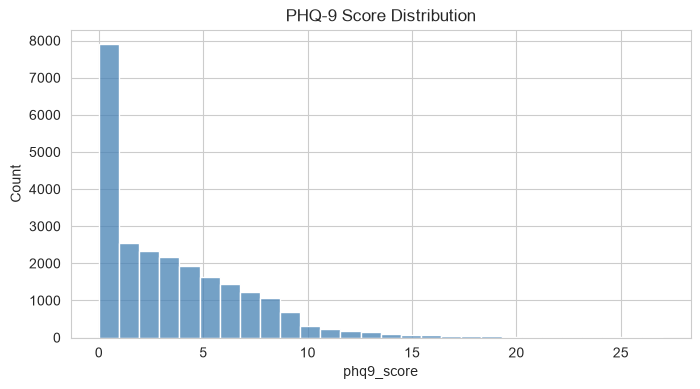

In [55]:
plt.figure(figsize=(8, 4))
sns.histplot(df["phq9_score"], bins=28, color="steelblue")
plt.title("PHQ-9 Score Distribution")
plt.show()

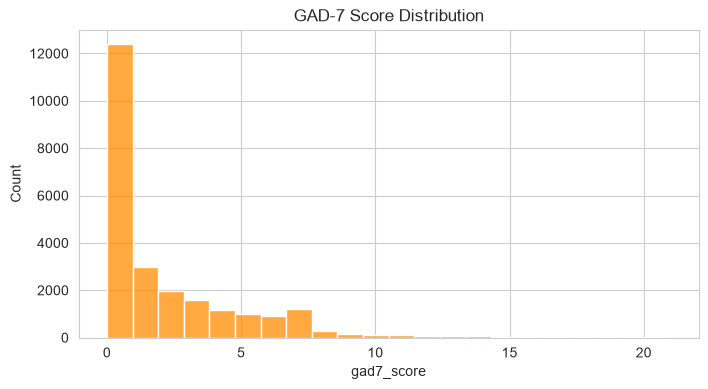

In [56]:
plt.figure(figsize=(8, 4))
sns.histplot(df["gad7_score"], bins=22, color="darkorange")
plt.title("GAD-7 Score Distribution")
plt.show()

Dono right-skewed hain. Zyada students ka score kam hai.

In [57]:
phq_pct = df["phq9_level"].value_counts(normalize=True).sort_index() * 100
gad_pct = df["gad7_level"].value_counts(normalize=True).sort_index() * 100
print(phq_pct.round(2))
print(gad_pct.round(2))

phq9_level
Minimal        69.52
Mild           25.09
Moderate        3.93
Mod. severe     1.07
Severe          0.39
Name: proportion, dtype: float64
gad7_level
Minimal     83.07
Mild        14.70
Moderate     1.58
Severe       0.65
Name: proportion, dtype: float64


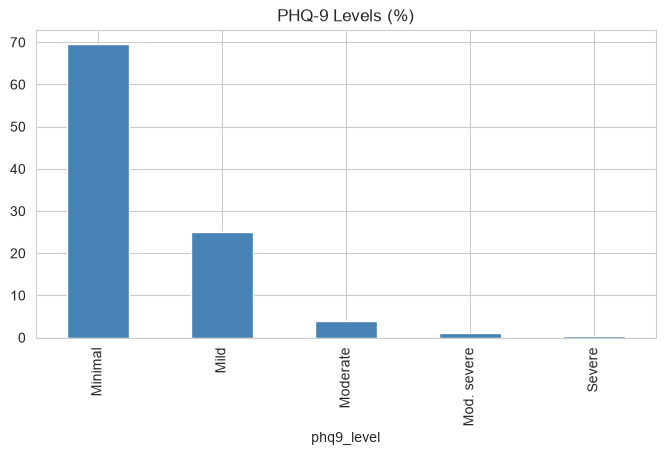

In [58]:
plt.figure(figsize=(8, 4))
phq_pct.plot(kind="bar", color="steelblue")
plt.title("PHQ-9 Levels (%)")
plt.show()

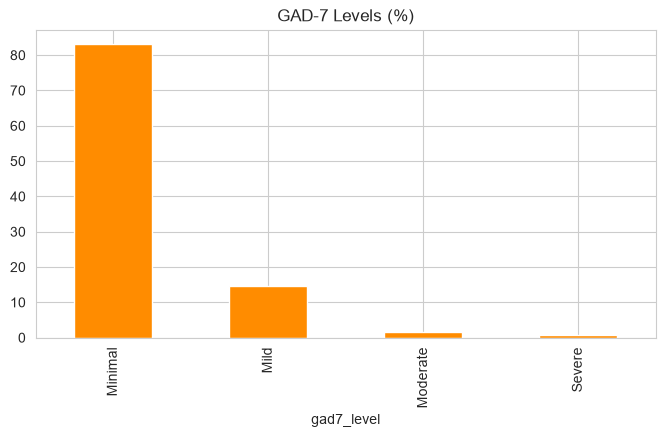

In [59]:
plt.figure(figsize=(8, 4))
gad_pct.plot(kind="bar", color="darkorange")
plt.title("GAD-7 Levels (%)")
plt.show()

Depression aur anxiety kitne related hain?

In [60]:
print("PHQ-9 vs GAD-7 correlation:", round(df["phq9_score"].corr(df["gad7_score"]), 3))

PHQ-9 vs GAD-7 correlation: 0.766


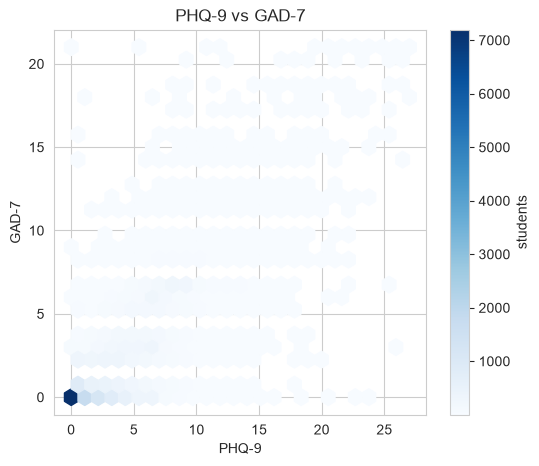

In [61]:
plt.figure(figsize=(6, 5))
plt.hexbin(df["phq9_score"], df["gad7_score"], gridsize=25, cmap="Blues", mincnt=1)
plt.colorbar(label="students")
plt.xlabel("PHQ-9")
plt.ylabel("GAD-7")
plt.title("PHQ-9 vs GAD-7")
plt.show()

Dono mein positive kitne students hain?

In [62]:
print(pd.crosstab(df["phq_pos"], df["gad_pos"], margins=True))

gad_pos      0    1    All
phq_pos                   
0        22814  131  22945
1          898  409   1307
All      23712  540  24252


In [63]:
print((pd.crosstab(df["phq_pos"], df["gad_pos"], normalize=True) * 100).round(2))

gad_pos      0     1
phq_pos             
0        94.07  0.54
1         3.70  1.69


Sleep (ISI) aur stress (PSS) ka link.

In [64]:
score_cols = ["phq9_score", "gad7_score", "isi_score", "pss_score"]
corr = df[score_cols].corr().round(2)
print(corr)

            phq9_score  gad7_score  isi_score  pss_score
phq9_score        1.00        0.77       0.65       0.50
gad7_score        0.77        1.00       0.60       0.49
isi_score         0.65        0.60       1.00       0.40
pss_score         0.50        0.49       0.40       1.00


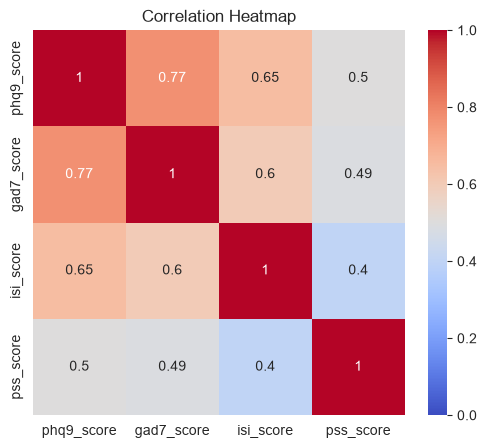

In [65]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

In [66]:
print(df.groupby("isi_level", observed=True)[["phq9_score", "gad7_score"]].mean().round(2))

              phq9_score  gad7_score
isi_level                           
None                2.71        1.50
Subthreshold        8.20        5.56
Moderate           12.25        8.71
Severe             16.33       13.25


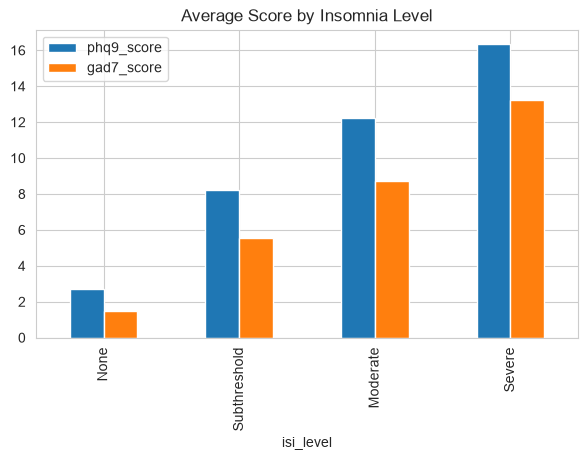

In [67]:
df.groupby("isi_level", observed=True)[["phq9_score", "gad7_score"]].mean().plot(kind="bar", figsize=(7, 4))
plt.title("Average Score by Insomnia Level")
plt.show()

Ab demographics. Pehle gender.

In [68]:
print(df.groupby("gender")[["phq9_score", "gad7_score", "isi_score", "pss_score"]].mean().round(2))

        phq9_score  gad7_score  isi_score  pss_score
gender                                              
female        3.34        1.99       2.77      19.81
male          3.12        1.76       2.78      20.29


In [69]:
print((df.groupby("gender")[["phq_pos", "gad_pos"]].mean() * 100).round(2))

        phq_pos  gad_pos
gender                  
female     5.17     2.20
male       5.77     2.28


Education, smoking, drinking. Pehle group size dekho, chhote groups ka average bharosemand nahi hota.

In [70]:
for col in ["edu", "smoke", "drink"]:
    print("\n", col)
    print(df.groupby(col)[["phq9_score", "gad7_score"]].agg(["mean", "count"]).round(2))


 edu
          phq9_score        gad7_score       
                mean  count       mean  count
edu                                          
associate       3.42   1278       2.02   1278
bachelor        3.27  22269       1.91  22269
doctorate       3.94     33       2.70     33
master          2.68    672       1.84    672

 smoke
           phq9_score        gad7_score       
                 mean  count       mean  count
smoke                                         
current          4.89    541       2.93    541
former           4.48    189       2.70    189
never            3.17  22481       1.85  22481
occasional       4.11   1041       2.46   1041

 drink
           phq9_score        gad7_score       
                 mean  count       mean  count
drink                                         
never            2.88  16377       1.69  16377
occasional       3.97   7351       2.31   7351
past             4.91    283       2.89    283
regular          5.88    241       3.37    24

Doctorate jaise chhote groups ko interpret karte waqt dhyan rakhna.

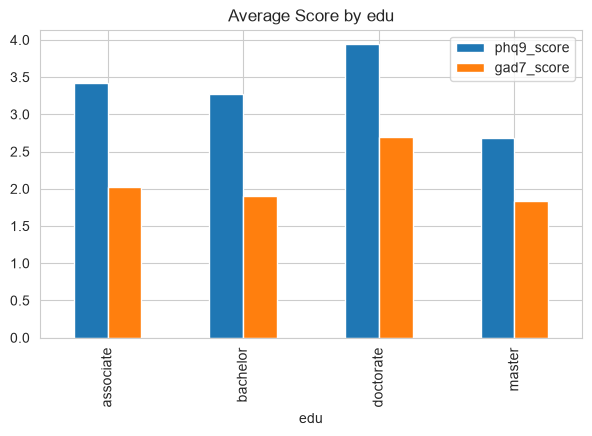

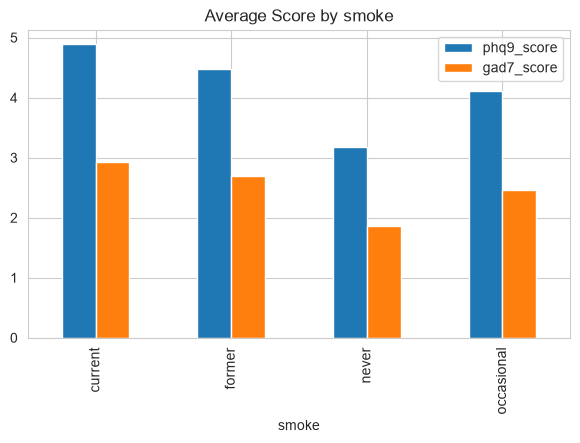

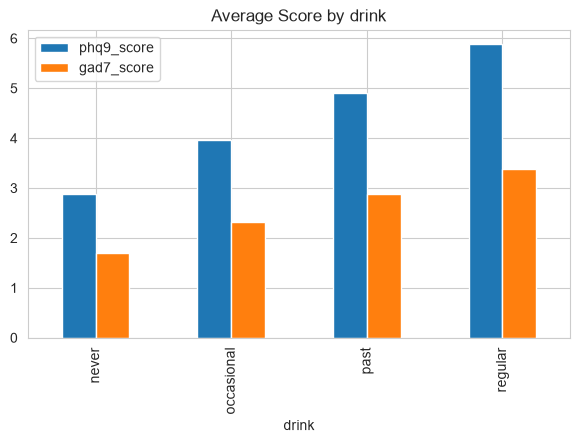

In [71]:
for col in ["edu", "smoke", "drink"]:
    df.groupby(col)[["phq9_score", "gad7_score"]].mean().plot(kind="bar", figsize=(7, 4))
    plt.title("Average Score by " + col)
    plt.show()

Age ke hisaab se score (17-28 age, kyunki baaki ke students bahut kam hain).

In [72]:
age_view = df[df["age"].between(17, 28)]
print(age_view["age"].value_counts().sort_index().head(3))

age
17     183
18    2609
19    4641
Name: count, dtype: int64


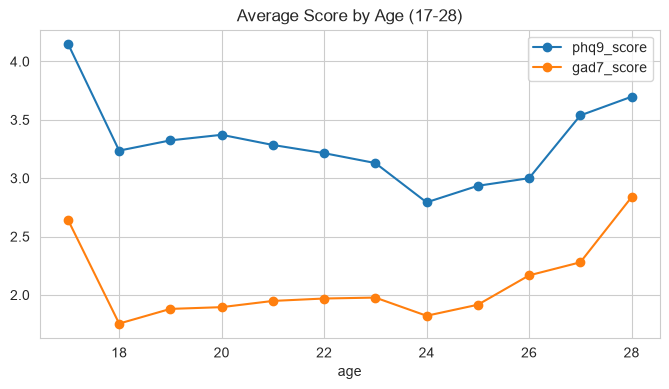

In [ ]:
age_view.groupby("age")[["phq9_score", "gad7_score"]].mean().plot(figsize=(8, 4), marker="o")
plt.title("Average Score by Age (17-28)")
plt.show()